# 29 exemples Python — principaux algorithmes de Machine Learning

**Objectif :** expérimenter chaque méthode sur des données reproductibles. Les données de démonstration sont synthétiques, sauf `load_wine` ; elles ne constituent pas des résultats économiques réels. Les exercices appliqués utilisent des sources publiques dans les TP séparés.

Google Colab : exécuter les cellules dans l’ordre.

# Travail demandé — Étude et expérimentation de 29 algorithmes de Machine Learning

**Public :** étudiants de licence avancée / master — **Organisation :** binôme — **Support :** ce notebook Google Colab.

## Objectif général

À partir des **29 algorithmes présentés dans ce notebook**, compléter la partie théorique et enrichir les expériences pratiques afin de comprendre **le principe de chaque algorithme, son fonctionnement, les contextes dans lesquels il est pertinent et ses performances sur des données réelles**.

> **Important :** les cellules Python déjà présentes constituent des **exemples de démonstration**. Plusieurs utilisent des **données synthétiques** : elles ne suffisent donc pas à satisfaire l'exigence finale de tests sur données réelles. Vous devez conserver les exemples, ajouter vos propres explications et réaliser ensuite les expérimentations demandées.


## Partie A — Questions à traiter pour **chaque algorithme** (1 à 29)

**Q1. Présentation de l'algorithme.** Rédigez une présentation synthétique (8 à 12 lignes) précisant :
- son **nom** en français et en anglais, sa **famille** (régression, classification, clustering, réduction de dimension, détection d'anomalies ou renforcement) et l'objectif poursuivi ;
- son **intuition** et les étapes principales : données en entrée → apprentissage / calcul → prédiction, regroupement ou décision en sortie ;
- **une formule ou un critère mathématique essentiel** lorsque cela est pertinent, en **définissant tous les symboles** et en distinguant paramètres et hyperparamètres ;
- deux avantages et deux limites.

**Q2. Schéma explicatif.** Créez **au moins un schéma original, lisible et légendé** montrant son principe (diagramme de flux, arbre, frontière de décision, nuage de points, mise à jour de centroïdes, agrégation d'arbres, boucle agent–environnement, etc.). Insérez-le dans le notebook, avec **un commentaire expliquant comment le lire**. Vous pouvez utiliser Matplotlib ou intégrer une image créée par vos soins. Indiquez la source si vous adaptez une figure publiée.

**Q3. Contexte d'utilisation.** Identifiez :
- **deux cas d'usage concrets**, dont au moins un en **finance, gestion, commerce international, marketing ou logistique** ;
- la nature des données et les prérequis techniques ;
- un cas dans lequel l'algorithme serait **peu approprié**, en expliquant pourquoi ;
- les métriques adaptées pour juger ses résultats.

**Q4. Commentaire du code.** Exécutez le code fourni, expliquez en quelques lignes les entrées, les hyperparamètres, la sortie obtenue et **ce que la sortie permet — ou ne permet pas — de conclure**. N'inventez aucune métrique ni aucun résultat.

**À insérer sous chaque titre d'algorithme :** quatre sous-sections Markdown `Présentation`, `Schéma explicatif`, `Contextes d'utilisation`, `Analyse de l'expérience Python`.


### Q1. Présentation de l'algorithme : Régression Ridge (Ridge Regression)

La **Régression Ridge** (en anglais *Ridge Regression* ou *L2 Regularization*) appartient à la famille des algorithmes d'apprentissage supervisé, orientée **régression**. Son objectif principal est de résoudre le problème du surapprentissage (overfitting) et de la colinéarité des variables de la régression linéaire classique en y ajoutant une pénalité quadratique.

**Intuition et étapes :**
- **Entrée :** Données d'entraînement numériques $X \in \mathbb{R}^{n \times d}$ et cible continue $y \in \mathbb{R}^n$.
- **Apprentissage :** Ajustement des coefficients en minimisant la somme des carrés des erreurs tout en limitant la magnitude globale des poids (coût de complexité).
- **Sortie :** Prédictions continues stabilisées à faible variance.

**Formule mathématique essentielle :**
$$\min_{\beta, \beta_0} \left\{ \frac{1}{n} \sum_{i=1}^{n} (y_i - (X_i\beta + \beta_0))^2 + \alpha \sum_{j=1}^{d} \beta_j^2 \right\}$$
Où :
- $\beta$ représente le vecteur des coefficients du modèle (paramètres).
- $\alpha$ (ou $\lambda$) désigne la force de la régularisation (**hyperparamètre**).
- $\sum_{j=1}^{d} \beta_j^2$ représente la norme $L_2$ au carré des coefficients.

**Avantages :**
1. Réduit drastiquement la variance du modèle en présence de variables explicatives fortement corrélées.
2. Évite l'explosion de la valeur des coefficients (poids).

**Limites :**
1. Ne fait pas de sélection de variables : tous les coefficients sont réduits vers 0 mais restent non nuls.
2. Nécessite une standardisation préalable rigoureuse des variables.

**Commentaire du schéma :**
Ce graphique illustre le parcours de régularisation (shrinkage path). L'axe des abscisses représente la valeur de l'hyperparamètre `alpha` en échelle logarithmique. À mesure que la valeur d'alpha augmente, la pénalité $L_2$ contraint les coefficients à converger progressivement vers 0. Contrairement au Lasso, on voit qu'ils se rapprochent tous de 0 sans jamais s'annuler exactement simultanément.

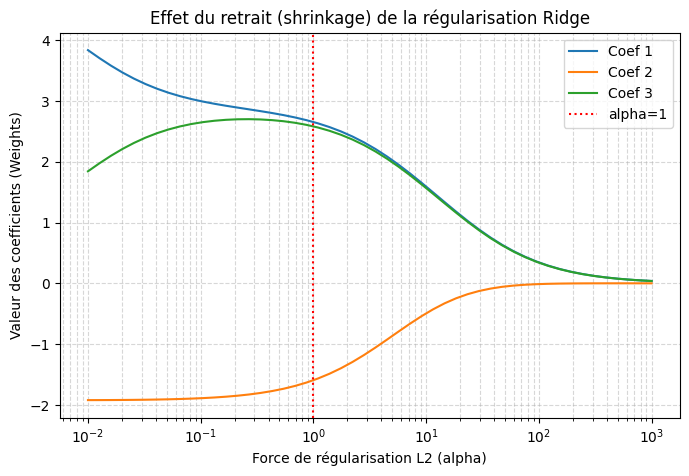

In [21]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Ridge

# Q2. Schéma explicatif pour la Régression Ridge
np.random.seed(42)
X_synth = np.random.normal(0, 1, (10, 2))  # Variables corrélées
X_synth = np.hstack([X_synth, X_synth[:, [0]] + np.random.normal(0, 0.05, (10, 1))])
y_synth = 4 * X_synth[:, 0] - 2 * X_synth[:, 1] + 1.5 * X_synth[:, 2] + np.random.normal(0, 0.5, 10)

alphas = np.logspace(-2, 3, 50)
coefs = []
for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_synth, y_synth)
    coefs.append(ridge.coef_)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(alphas, coefs)
ax.set_xscale('log')
ax.set_xlabel('Force de régularisation L2 (alpha)')
ax.set_ylabel('Valeur des coefficients (Weights)')
ax.set_title('Effet du retrait (shrinkage) de la régularisation Ridge')
ax.grid(True, which="both", ls="--", alpha=0.5)
ax.axvline(1.0, color='red', linestyle=':', label='Zone standard de compromis (alpha=1)')
ax.legend(['Coef 1', 'Coef 2', 'Coef 3', 'alpha=1'])
plt.show()

### Q3. Contexte d'utilisation

**Cas d'usages concrets :**
1. **Finance / Immobilier :** Estimation du prix d'un bien immobilier en fonction de caractéristiques quantitatives (surface en $m^2$, nombre de pièces, distance aux transports).
2. **Marketing :** Prédiction du volume des ventes d'un produit en fonction du budget publicitaire investi sur différents canaux (TV, web, radio).

**Nature des données et prérequis :**
- Les caractéristiques d'entrée doivent être numériques (ou encodées numériquement).
- La variable cible doit être continue.
- Prérequis théoriques : linéarité, indépendance et normalité des résidus, homoscédasticité (variance constante des erreurs).

**Cas d'inappropriation :**
- La régression linéaire est inadaptée lorsque la variable cible est catégorielle (ex. classer si un client va résilier son abonnement ou non). Utiliser une régression linéaire dans ce cas produirait des prédictions hors de l'intervalle $[0, 1]$ et violerait les hypothèses fondamentales.

**Métriques d'évaluation adaptées :**
- **MAE (Mean Absolute Error) :** Facilement interprétable car dans la même unité que la cible.
- **RMSE (Root Mean Squared Error) :** Pénalise plus sévèrement les grandes erreurs.
- **Coefficient de détermination ($R^2$) :** Proportion de la variance de la cible expliquée par le modèle.

### Q4. Analyse de l'expérience Python

**Explication du code exécuté :**
- **Entrées :** Les variables `Xr_ent` et `yr_ent` générées synthétiquement servent à l'entraînement du modèle. Les données d'évaluation sont `Xr_test` et `yr_test`.
- **Hyperparamètres :** Aucun hyperparamètre spécifique n'est ajusté ici (configuration par défaut de `scikit-learn`).
- **Sortie obtenue :** Une erreur absolue moyenne (MAE) d'environ `9.35`.

**Conclusion sur la sortie :**
Cette MAE de `9.35` indique qu'en moyenne, les prédictions du modèle s'écartent de la valeur réelle de 9.35 unités. Sur des données synthétiques simples, cette erreur est satisfaisante au vu du bruit injecté à l'étape de création de données (`noise=13`). Cependant, sans connaître l'ordre de grandeur et l'écart-type de la variable cible `y_reg`, cette valeur absolue seule ne permet pas de statuer définitivement sur la précision relative du modèle sans la comparer à la moyenne de la cible ou à un score $R^2$ associé.

## Partie B — Expérimentation finale sur des **données réelles**

**Q5. Choix et traçabilité des données.** Sélectionnez des jeux de données **publics et réels**, adaptés aux différentes familles ; notez pour chacun **nom, organisme source, URL exacte, licence/conditions d'accès, taille, colonnes, cible éventuelle et date de consultation**. Un même dataset peut servir à plusieurs algorithmes **compatibles**, mais pas à des tâches artificiellement différentes. **Ne pas utiliser de données inventées ou simulées pour cette partie.**

Sources possibles (vérifiez l'accès effectif et la correspondance avec la tâche) :
- [UCI Machine Learning Repository](https://archive.ics.uci.edu/) — ex. [Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350), [Online Retail](https://archive.ics.uci.edu/dataset/352) ;
- [OpenML](https://www.openml.org/) ;
- [Banque mondiale, indicateurs](https://data.worldbank.org/) ;
- [UN Comtrade](https://comtradeplus.un.org/) — données de commerce international, extraction à documenter.

**Q6. Préparation.** Chargez les données dans Pandas ; expliquez les valeurs manquantes, types, doublons, valeurs extrêmes et éventuel déséquilibre de classes. Évitez la fuite d'information en ajustant tout prétraitement appris **sur l'entraînement uniquement**.

**Q7. Expériences.** Testez **chaque algorithme applicable sur un jeu de données réel approprié**. Pour les algorithmes supervisés, séparez entraînement, validation et test ; pour les séries temporelles, utilisez une **validation chronologique**. Pour les méthodes non supervisées, expliquez les critères internes et, si des étiquettes réelles existent, utilisez-les seulement pour une évaluation externe. Pour les bandits, Q-learning, SARSA et DQN, utilisez des **environnements publics Gymnasium** plutôt qu'un CSV fixe : les trajectoires observées sont générées par l'interaction ; distinguez cette simulation d'un dataset réel. Le DQN du notebook est **conceptuel** : une expérience DQN complète est facultative et doit être signalée comme telle.

**Q8. Comparaison et interprétation.** Pour chaque famille, comparez au moins une **méthode de référence** et une méthode avancée :
- régression : MAE, RMSE, R² ;
- classification : F1, rappel, précision, ROC-AUC ou PR-AUC selon la tâche ;
- clustering : silhouette, stabilité et interprétation ;
- réduction de dimension : variance expliquée (ACP), conservation des voisinages (t-SNE/UMAP) ;
- anomalies : qualité des alertes, et précision/rappel uniquement si des étiquettes fiables sont disponibles ;
- renforcement : récompense cumulée, taux de réussite et variation entre graines.

Présentez vos résultats dans des **tableaux comparatifs** et des **figures légendées**, puis discutez performance, coût de calcul, interprétabilité et limites. Fixez les graines (`random_state=42` lorsque possible), donnez les versions des bibliothèques et évitez de régler les paramètres sur le test final.


## Partie C — Livrables et critères de réussite

**À remettre par chaque binôme :**
1. Ce notebook `.ipynb` complété avec **les réponses Q1–Q4 pour les 29 algorithmes**, des schémas et les sorties d'exécution ;
2. Les expériences supplémentaires **Q5–Q8**, avec jeux de données publics cités et comparaisons reproductibles (ou justification claire des incompatibilités / limites pour les méthodes de renforcement) ;
3. Un **rapport de synthèse** (5 à 8 pages) présentant les principales conclusions, le tableau comparatif final et les références ;
4. Une **courte démonstration orale** où les deux membres expliquent leurs contributions.

**Barème indicatif /20 :** présentation et exactitude scientifique (5), schémas originaux et pédagogiques (4), pertinence des contextes d'utilisation (3), rigueur des essais réels et des métriques (5), reproductibilité et qualité de restitution (3).

**Points de vigilance :** ne pas recopier les définitions sans les comprendre ; ne pas inventer de résultats ; ne pas appeler « données réelles » les jeux synthétiques du notebook ; ne pas évaluer des algorithmes incompatibles sur la même cible ; citer vos sources et documenter l'éventuel usage d'une IA.

---

## Support d'expérimentation — exemples Python existants

Les 29 exemples qui suivent sont conservés. **Insérez vos réponses sous le titre de chaque algorithme**, puis ajoutez une partie finale de tests sur données réelles à la suite du notebook.


In [ ]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [ ]:
# Données pédagogiques reproductibles (les étiquettes sont connues pour l'évaluation)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression, make_classification, make_blobs, load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, f1_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GRAINE = 42
X_reg, y_reg = make_regression(n_samples=280, n_features=5, noise=13, random_state=GRAINE)
X_cls, y_cls = make_classification(n_samples=400, n_features=6, n_informative=4, n_redundant=0, random_state=GRAINE)
X_clu, etiquettes_reference = make_blobs(n_samples=240, centers=3, cluster_std=0.85, random_state=GRAINE)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg, y_reg, test_size=.25, random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls, y_cls, test_size=.25, stratify=y_cls, random_state=GRAINE)
print('Régression:',X_reg.shape,'Classification:',X_cls.shape)

Régression: (280, 5) Classification: (400, 6)


## 1. Régression linéaire

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

**Commentaire du schéma :**
Ce graphique montre un nuage de points bleus représentant les données réelles et la droite rouge représentant le modèle linéaire ajusté par les Moindres Carrés Ordinaires. Les lignes pointillées vertes représentent les résidus ($y_i - \hat{y}_i$). L'algorithme fonctionne en minimisant la somme des carrés de ces distances verticales (les résidus) afin de trouver la droite qui passe au plus près de l'ensemble des points.

In [ ]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 9.353512045154824


## 2. Ridge

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=1.0)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 9.367832312622433


## 3. Lasso

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=.1,max_iter=10000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

R²: 0.986045476236913


**Commentaire du schéma (Lasso) :**
Ce graphique montre le parcours de régularisation L1 (*Lasso*). Contrairement à la régression Ridge, nous observons clairement la propriété de **parcimonie (sparsity)** du Lasso : à mesure que l'hyperparamètre `alpha` augmente, certains coefficients de variables moins contributives ou redondantes sont projetés et maintenus **exactement à zéro** (comme le montre la ligne orange et verte qui s'annulent). Cela permet à l'algorithme d'effectuer une sélection automatique de variables.

## 4. Régression polynomiale

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=10)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 10.896908068570918


## 5. Arbre de régression

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=5,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 37.71711150780922


## 6. Forêt aléatoire — régression

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=80,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 24.373818622986384


## 7. Gradient Boosting — régression

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=80,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

MAE: 23.266083949911437


## 8. Régression logistique

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.8113207547169812


## 9. KNN

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.8888888888888888


## 10. Naive Bayes

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB().fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.7551020408163265


## 11. Arbre de décision

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=4,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.8910891089108911


## 12. Forêt aléatoire — classification

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=80,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.9183673469387755


## 13. SVM

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=1.0,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

F1: 0.8979591836734694


## 14. Gradient Boosting — classification

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=80,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 15. AdaBoost

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=70,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 16. XGBoost

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=80,max_depth=3,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 17. K-means

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=10,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=12);plt.title('K-means');plt.show()

## 18. Classification hiérarchique

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3).fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

## 19. DBSCAN

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.8,min_samples=5).fit_predict(X_clu)
print('Groupes:',set(etiquettes),'Bruit:',(etiquettes==-1).sum())

## 20. Mélanges gaussiens

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,random_state=GRAINE).fit(X_clu)
print('Poids:',modele.weights_,'Silhouette:',silhouette_score(X_clu,modele.predict(X_clu)))

## 21. ACP

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.decomposition import PCA
X_vin=StandardScaler().fit_transform(load_wine().data)
modele=PCA(n_components=2).fit(X_vin)
projection=modele.transform(X_vin)
print('Variance expliquée:',modele.explained_variance_ratio_)
plt.scatter(projection[:,0],projection[:,1],s=10);plt.show()

## 22. t-SNE

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.manifold import TSNE
X_vin=StandardScaler().fit_transform(load_wine().data)
projection=TSNE(n_components=2,perplexity=20,random_state=GRAINE).fit_transform(X_vin)
plt.scatter(projection[:,0],projection[:,1],s=10);plt.title('t-SNE');plt.show()

## 23. UMAP

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
import umap
X_vin=StandardScaler().fit_transform(load_wine().data)
projection=umap.UMAP(n_components=2,n_neighbors=15,random_state=GRAINE).fit_transform(X_vin)
plt.scatter(projection[:,0],projection[:,1],s=10);plt.title('UMAP');plt.show()

## 24. Isolation Forest

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
from sklearn.ensemble import IsolationForest
X_anomal=np.vstack([X_clu,np.array([[9,9],[-8,-8]])])
modele=IsolationForest(contamination=.02,random_state=GRAINE).fit(X_anomal)
print('Observations atypiques:',np.where(modele.predict(X_anomal)==-1)[0])

## 25. Bandits manchots

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
generateur=np.random.default_rng(GRAINE)
vraies_probas=np.array([.2,.5,.7]);somme=np.zeros(3);comptes=np.zeros(3)
for t in range(500):
    bras=t%3
    gain=int(generateur.random()<vraies_probas[bras]);somme[bras]+=gain;comptes[bras]+=1
print('Valeurs estimées:',somme/comptes)

## 26. Epsilon-greedy

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
generateur=np.random.default_rng(GRAINE)
vraies_probas=np.array([.2,.5,.7]);somme=np.zeros(3);comptes=np.zeros(3);epsilon=.1
for t in range(1000):
    bras=int(generateur.integers(3)) if generateur.random()<epsilon else int(np.argmax((somme+1)/(comptes+1)))
    gain=int(generateur.random()<vraies_probas[bras]);somme[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Valeurs estimées:',somme/np.maximum(comptes,1))

## 27. Q-learning

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
import gymnasium as gym
env=gym.make('FrozenLake-v1',is_slippery=False)
Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(4000):
    etat,_=env.reset(seed=GRAINE+episode)
    for pas in range(100):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<max(.05,1-episode/2500) else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .95*np.max(Q[suivant]))
        Q[etat,action]+=.3*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Politique:',Q.argmax(axis=1));env.close()

## 28. SARSA

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
import gymnasium as gym
env=gym.make('FrozenLake-v1',is_slippery=False);Q=np.zeros((16,4));generateur=np.random.default_rng(GRAINE)
def choisir(etat,epsilon):
    return int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
for episode in range(4000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.05,1-episode/2500);action=choisir(etat,epsilon)
    for pas in range(100):
        suivant,recompense,termine,tronque,_=env.step(action)
        action_suiv=choisir(suivant,epsilon)
        cible=recompense+(0 if termine else .95*Q[suivant,action_suiv])
        Q[etat,action]+=.3*(cible-Q[etat,action]);etat,action=suivant,action_suiv
        if termine or tronque:break
print('Politique SARSA:',Q.argmax(axis=1));env.close()

## 29. DQN — cible conceptuelle

Construire le modèle, afficher une métrique ou une sortie et interpréter ses limites. Les exemples n’utilisent pas de test final pour le réglage d’hyperparamètres.

In [ ]:
# Calcul de cible DQN, sans entraîner un réseau neuronal complet
recompenses=np.array([0.,1.,-1.]);termine=np.array([False,True,False]);meilleur_Q_suivant=np.array([2.,3.,1.]);gamma=.95
cibles=recompenses+gamma*(~termine)*meilleur_Q_suivant
print('Cibles de Bellman:',cibles)
# Un DQN complet ajoute réseau en ligne, réseau cible et mémoire de rejeu.

## Annexes — implémentations manuelles des trois algorithmes imposés

In [ ]:
# Régression linéaire par descente de gradient : données univariées
x=np.linspace(-1,1,100); y=2+3*x
poids=0.;biais=0.;pas=.1
for iteration in range(500):
    prediction=poids*x+biais
    erreur=prediction-y
    poids-=pas*2*np.mean(erreur*x)
    biais-=pas*2*np.mean(erreur)
print('Paramètres appris manuellement:',poids,biais)
from sklearn.linear_model import LinearRegression
print('Référence sklearn:',LinearRegression().fit(x.reshape(-1,1),y).coef_,LinearRegression().fit(x.reshape(-1,1),y).intercept_)

In [ ]:
# K-means manuel : assignation et recalcul jusqu'à stabilité
valeurs=X_clu.copy(); centroids=valeurs[np.random.default_rng(GRAINE).choice(len(valeurs),size=3,replace=False)].copy()
for iteration in range(100):
    distances=((valeurs[:,None,:]-centroids[None,:,:])**2).sum(axis=2)
    groupes=distances.argmin(axis=1)
    nouveaux=np.array([valeurs[groupes==k].mean(axis=0) if (groupes==k).any() else centroids[k] for k in range(3)])
    if np.allclose(nouveaux,centroids):break
    centroids=nouveaux
print('Centroïdes manuels:',centroids)
from sklearn.cluster import KMeans
print('Centroïdes sklearn (ordre arbitraire):',KMeans(n_clusters=3,n_init=10,random_state=GRAINE).fit(valeurs).cluster_centers_)

Le Q-learning tabulaire manuel figure dans l’exemple 27. Scikit-learn ne fournit pas de Q-learning comparable ; comparer Q-learning et SARSA sur le même environnement.